# TP3 – Analyse Big Data des accidents de la route avec PySpark

Reproduction de l'étude de Rakesh Nain : *Big data Analysis of Road Crash Data using PySpark with PySpark Tutorial*
([article Medium](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588),
[dépôt GitHub de l'auteur](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial)).

Ce TP prolonge les deux précédents (comptage de mots en MapReduce puis en PySpark) : on applique les mêmes outils
(RDD, DataFrame, Spark SQL) à un vrai jeu de données, et on commence d'ailleurs par un comptage de mots sur ces données.

## 1. Problème

**Données.** Accidents de la route en Australie-Méridionale de 2012 à 2019, publiés par le *Department of Planning,
Transport and Infrastructure* (DPTI) sur [data.sa.gov.au](https://data.sa.gov.au). Comme dans l'article, on utilise deux tables :

| Table | Fichiers | Une ligne = | Colonnes utiles |
|---|---|---|---|
| **Crash** | `crash_data/20XX_DATA_SA_Crash.csv` (8 fichiers) | un accident | `REPORT_ID`, `Suburb`, `Total Cas` (victimes), `Total Fats` (tués), `Year/Month/Day/Time`, `Crash Type`, `CSEF Severity`, `DUI Involved` (alcool), `Drugs Involved` |
| **Units** | `units_data/20XX_DATA_SA_Units.csv` (8 fichiers) | un véhicule / piéton impliqué | `REPORT_ID`, `Veh Reg State`, `Unit Type`, `Veh Year`, `Sex`, `Age`, `Lic State`, `Licence Type` |

Les deux tables se joignent sur `REPORT_ID`. La gravité `CSEF Severity` a quatre niveaux : `1: PDO` (dégâts matériels seuls),
`2: MI` (blessure légère), `3: SI` (blessure grave), `4: Fatal`.

**Questions de l'étude** (reprises de l'article) :
1. Partitionner les véhicules en « immatriculés en Australie-Méridionale » / « autres ».
2. Âge moyen des conducteurs hommes et femmes.
3. Véhicules les plus anciens et les plus récents impliqués.
4. Accidents à Adélaïde avec plus de 3 victimes ; 10 accidents les plus graves ; tués par type d'accident.
5. Victimes par quartier quand le conducteur n'a pas de permis.
6. La gravité est-elle plus forte quand le conducteur est sous drogue et/ou alcool ?
7. Mêmes requêtes écrites avec les trois API (RDD, DataFrame, SQL) puis comparées.

On ajoute à l'étude originale : un comptage de mots sur les types d'accident (lien avec les TP précédents),
des **tests** automatiques de cohérence, une **comparaison chiffrée** des trois API et la correction de deux erreurs de l'article (voir §9).

## 2. Principe

Spark découpe les données en **partitions** traitées en parallèle par les cœurs de la machine (`local[*]`) ou les nœuds d'un cluster.
Les **transformations** (`map`, `filter`, `join`, `groupBy`…) sont paresseuses ; seules les **actions** (`count`, `collect`, `show`) lancent le calcul.

- **RDD** : collection distribuée d'objets Python. Contrôle total, mais pas d'optimiseur et chaque ligne passe par un worker Python.
- **DataFrame** : table avec schéma, optimisée par Catalyst et exécutée dans la JVM.
- **Spark SQL** : même moteur que les DataFrames, avec une syntaxe SQL.

C'est le même modèle que le comptage de mots : `map` → clé/valeur, `reduceByKey`/`groupBy` → agrégation.

## 3. Installation

```bash
pip install pyspark==3.5.3 pandas matplotlib
```
Java 17 doit être installé (`java -version`).

**Sous Windows**, Spark a besoin de `winutils.exe` et `hadoop.dll` (Hadoop 3.3.x, par ex. depuis le dépôt `cdarlint/winutils`)
dans `%HADOOP_HOME%in`, ce dossier étant aussi dans le `PATH` ; sans eux, la lecture des fichiers échoue (`UnsatisfiedLinkError`).

## 4. Récupération des données

Les CSV sont téléchargés depuis le dépôt de l'auteur (exactement les fichiers utilisés dans l'article, ~77 Mo).
Ils ne sont pas versionnés dans ce dépôt (voir `.gitignore`).

In [1]:
import os, sys, urllib.request

BASE = "https://raw.githubusercontent.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/master"
YEARS = range(2012, 2020)
for folder, suffix in [("crash_data", "Crash"), ("units_data", "Units")]:
    os.makedirs(folder, exist_ok=True)
    for y in YEARS:
        path = f"{folder}/{y}_DATA_SA_{suffix}.csv"
        if not os.path.exists(path):
            urllib.request.urlretrieve(f"{BASE}/{folder}/{y}_DATA_SA_{suffix}.csv", path)
        print(path, f"{os.path.getsize(path)/1e6:.1f} Mo")

crash_data/2012_DATA_SA_Crash.csv 7.5 Mo
crash_data/2013_DATA_SA_Crash.csv 5.6 Mo
crash_data/2014_DATA_SA_Crash.csv 5.4 Mo
crash_data/2015_DATA_SA_Crash.csv 5.2 Mo
crash_data/2016_DATA_SA_Crash.csv 5.6 Mo
crash_data/2017_DATA_SA_Crash.csv 4.4 Mo
crash_data/2018_DATA_SA_Crash.csv 4.6 Mo
crash_data/2019_DATA_SA_Crash.csv 4.3 Mo
units_data/2012_DATA_SA_Units.csv 6.7 Mo
units_data/2013_DATA_SA_Units.csv 5.0 Mo
units_data/2014_DATA_SA_Units.csv 4.8 Mo
units_data/2015_DATA_SA_Units.csv 4.6 Mo
units_data/2016_DATA_SA_Units.csv 5.0 Mo
units_data/2017_DATA_SA_Units.csv 3.9 Mo
units_data/2018_DATA_SA_Units.csv 4.0 Mo
units_data/2019_DATA_SA_Units.csv 3.8 Mo


## 5. Création de la session Spark

In [2]:
import csv, time
from pyspark import SparkConf
from pyspark.sql import SparkSession
from pyspark.rdd import RDD
from pyspark.sql.functions import col
from pyspark.sql.types import IntegerType
import pyspark.sql.functions as F
import pandas as pd
import matplotlib.pyplot as plt

# Les workers Python utilisent le même interpréteur que le notebook
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# local[*, 4] : tous les cœurs, et jusqu'à 4 tentatives par tâche (comme sur un cluster).
# Sous Windows, les workers Python de Spark 3.5 plantent parfois aléatoirement (WinError 10053) ;
# la relance automatique rend l'exécution fiable sans changer les résultats.
conf = SparkConf().setMaster("local[*, 4]").setAppName("Big data Analysis of Road Crash Data")
spark = SparkSession.builder.config(conf=conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")
print("Spark", spark.version, "-", sc.defaultParallelism, "cœurs")

Spark 3.5.3 - 12 cœurs


## 6. Analyse avec les RDD

### 6.1 Chargement

`textFile` lit tous les fichiers d'un motif et renvoie un RDD de lignes. On retire l'en-tête (répété dans chaque fichier).

L'article découpe les lignes avec `line.split(',')`, ce qui casse les champs entre guillemets contenant une virgule.
On utilise ici le module `csv`, qui gère correctement les guillemets.

In [3]:
def parse_csv(line):
    return next(csv.reader([line]))

units_raw = sc.textFile("./units_data/*.csv")
crash_raw = sc.textFile("./crash_data/*.csv")

# L'en-tête est répété dans chaque fichier : toutes les lignes commençant par "REPORT_ID" sont retirées.
# (L'article utilise rdd.first() ; sous Windows, first()/take() font planter le worker Python de Spark 3.5,
#  on lit donc l'en-tête directement dans un des fichiers. Pour la même raison les RDD ne sont pas mis en cache :
#  sous Windows, cache() suivi d'une jointure RDD fait aussi planter les workers.)
units_header = open("units_data/2019_DATA_SA_Units.csv", encoding="utf-8").readline().strip()
crash_header = open("crash_data/2019_DATA_SA_Crash.csv", encoding="utf-8").readline().strip()
is_data = lambda l: not l.startswith('"REPORT_ID"')
units_rdd = units_raw.filter(is_data).map(parse_csv)
crash_rdd = crash_raw.filter(is_data).map(parse_csv)

U = {name: i for i, name in enumerate(parse_csv(units_header))}   # nom de colonne -> indice
C = {name: i for i, name in enumerate(parse_csv(crash_header))}

print("Units :", units_rdd.count(), "lignes,", units_rdd.getNumPartitions(), "partitions")
print("Crash :", crash_rdd.count(), "lignes,", crash_rdd.getNumPartitions(), "partitions")
crash_rdd.takeOrdered(2)

Units : 272591 lignes, 8 partitions


Crash : 127672 lignes, 8 partitions


[['2012-1-21/08/2019',
  '2 Metropolitan',
  'STEPNEY',
  '5069',
  'CC OF NORWOOD,PAYNEHAM & ST PETERS',
  '2',
  '0',
  '0',
  '0',
  '0',
  '2012',
  'January',
  'Sunday',
  '04:30 pm',
  '060',
  'Not Divided',
  'Straight road',
  'Level',
  'Driveway or Entrance',
  'Sealed',
  'Dry',
  'Not Raining',
  'Daylight',
  'Right Angle',
  '02',
  'Driver Rider',
  '1: PDO',
  'No Control',
  '',
  '',
  '1330659.71',
  '1671795.87',
  '13306601671796'],
 ['2012-10-21/08/2019',
  '2 Metropolitan',
  'PROSPECT',
  '5082',
  'CITY OF PROSPECT',
  '2',
  '0',
  '0',
  '0',
  '0',
  '2012',
  'January',
  'Saturday',
  '03:00 pm',
  '050',
  'Pedestrian Crossing',
  'Straight road',
  'Level',
  'Not Applicable',
  'Sealed',
  'Dry',
  'Not Raining',
  'Daylight',
  'Rear End',
  '01',
  'Driver Rider',
  '1: PDO',
  'Traffic Signals',
  '',
  '',
  '',
  '',
  '']]

### 6.2 Partitionnement personnalisé

Par défaut, Spark répartit les lignes de façon équilibrée. On crée ici deux partitions : véhicules dont le conducteur a un
permis d'Australie-Méridionale (`Lic State == 'SA'`, colonne utilisée par l'article) et tous les autres.

In [4]:
def hash_SA(key):
    return 0 if key == "SA" else 1

units_state_rdd = units_rdd.map(lambda r: (r[U["Lic State"]], r))
SA_partitioned_rdd = units_state_rdd.partitionBy(2, hash_SA)

def print_partitions(data):
    rdd = data if isinstance(data, RDD) else data.rdd
    sizes = rdd.glom().map(len).collect()
    print("Nombre de partitions :", len(sizes))
    for i, n in enumerate(sizes):
        print(f"  Partition {i} : {n} lignes")
    return sizes

partition_sizes = print_partitions(SA_partitioned_rdd)

Nombre de partitions : 2
  Partition 0 : 198646 lignes
  Partition 1 : 73945 lignes


Comme attendu pour des données d'Australie-Méridionale, la partition `SA` est de loin la plus grande.

### 6.3 Âge moyen des conducteurs par sexe

In [5]:
def gender_age(r):
    sex, age = r[U["Sex"]], r[U["Age"]]
    if age.isdigit() and sex in ("Male", "Female"):
        return [(sex, int(age))]
    return []

# moyenne = somme / effectif, calculés en une passe avec reduceByKey (plus efficace que groupByKey)
age_avg = (units_rdd.flatMap(gender_age)
           .mapValues(lambda a: (a, 1))
           .reduceByKey(lambda x, y: (x[0] + y[0], x[1] + y[1]))
           .mapValues(lambda s: round(s[0] / s[1], 2)))
age_avg.collect()

[('Male', 40.8), ('Female', 40.08)]

Les âges moyens des hommes et des femmes impliqués sont très proches, comme le conclut l'article.

### 6.4 Véhicules les plus anciens et les plus récents

In [6]:
year_rdd = (units_rdd.filter(lambda r: r[U["Veh Year"]].isdigit())
            .map(lambda r: (int(r[U["Veh Year"]]), (r[U["Veh Reg State"]], r[U["Unit Type"]]))))
# takeOrdered évite de tout trier puis tout collecter (l'article fait sortByKey().collect()[0:5])
print("5 plus anciens :", year_rdd.takeOrdered(5, key=lambda x: x[0]))
print("5 plus récents :", year_rdd.takeOrdered(5, key=lambda x: -x[0]))

5 plus anciens : [(1900, ('VIC', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle'))]


5 plus récents : [(2019, ('SA', 'Station Wagon')), (2019, ('SA', 'OMNIBUS')), (2019, ('SA', 'Motor Cars - Sedan')), (2019, ('SA', 'Station Wagon')), (2019, ('SA', 'SEMI TRAILER'))]


Certaines années (ex. avant 1900 ou postérieures à l'accident) sont manifestement des erreurs de saisie : les données réelles
nécessitent un nettoyage avant d'en tirer des conclusions.

## 7. Le même exemple : comptage de mots sur les types d'accident

On reprend exactement le *word count* des TP précédents, appliqué à la colonne `Crash Type` :
`flatMap` (découpe en mots) → `map` (mot, 1) → `reduceByKey` (somme).

In [7]:
words = (crash_rdd.flatMap(lambda r: r[C["Crash Type"]].lower().split())
         .map(lambda w: (w, 1))
         .reduceByKey(lambda a, b: a + b))
top_words = words.takeOrdered(10, key=lambda x: -x[1])
top_words

[('rear', 37218),
 ('end', 37218),
 ('right', 34319),
 ('hit', 33896),
 ('angle', 24236),
 ('object', 19858),
 ('fixed', 19365),
 ('side', 13111),
 ('swipe', 13111),
 ('turn', 10083)]

In [8]:
# Même calcul en DataFrame et comptage direct des types (sans découpe en mots)
crash_type_counts = (crash_rdd.map(lambda r: (r[C["Crash Type"]], 1))
                     .reduceByKey(lambda a, b: a + b)
                     .takeOrdered(10, key=lambda x: -x[1]))
crash_type_counts

[('Rear End', 37218),
 ('Right Angle', 24236),
 ('Hit Fixed Object', 19365),
 ('Side Swipe', 13111),
 ('Right Turn', 10083),
 ('Hit Parked Vehicle', 9148),
 ('Roll Over', 5304),
 ('Hit Pedestrian', 2848),
 ('Head On', 2086),
 ('Hit Animal', 2042)]

Les collisions par l'arrière (*rear end*) et à angle droit (*right angle*) dominent, devant les sorties de route.

## 8. Analyse avec les DataFrames

### 8.1 Chargement

`spark.read.csv` gère l'en-tête, les guillemets et l'union des fichiers. On convertit les colonnes numériques utilisées.

In [9]:
units_df = spark.read.option("header", True).option("escape", '"').csv("./units_data/*.csv")
crash_df = (spark.read.option("header", True).option("escape", '"').csv("./crash_data/*.csv")
            .withColumn("Total Cas", col("Total Cas").cast(IntegerType()))
            .withColumn("Total Fats", col("Total Fats").cast(IntegerType())))
units_df.cache(); crash_df.cache()
print(units_df.count(), crash_df.count())
crash_df.printSchema()

272591 127672
root
 |-- REPORT_ID: string (nullable = true)
 |-- Stats Area: string (nullable = true)
 |-- Suburb: string (nullable = true)
 |-- Postcode: string (nullable = true)
 |-- LGA Name: string (nullable = true)
 |-- Total Units: string (nullable = true)
 |-- Total Cas: integer (nullable = true)
 |-- Total Fats: integer (nullable = true)
 |-- Total SI: string (nullable = true)
 |-- Total MI: string (nullable = true)
 |-- Year: string (nullable = true)
 |-- Month: string (nullable = true)
 |-- Day: string (nullable = true)
 |-- Time: string (nullable = true)
 |-- Area Speed: string (nullable = true)
 |-- Position Type: string (nullable = true)
 |-- Horizontal Align: string (nullable = true)
 |-- Vertical Align: string (nullable = true)
 |-- Other Feat: string (nullable = true)
 |-- Road Surface: string (nullable = true)
 |-- Moisture Cond: string (nullable = true)
 |-- Weather Cond: string (nullable = true)
 |-- DayNight: string (nullable = true)
 |-- Crash Type: string (nullabl

### 8.2 Accidents à Adélaïde avec plus de 3 victimes

In [10]:
adelaide_df = crash_df.filter((col("Total Cas") > 3) & (col("Suburb") == "ADELAIDE"))
adelaide_df.select("REPORT_ID", "Year", "Month", "Day", "Time", "Total Cas", "Crash Type").show(truncate=False)

+---------------------+----+--------+--------+--------+---------+--------------+
|REPORT_ID            |Year|Month   |Day     |Time    |Total Cas|Crash Type    |
+---------------------+----+--------+--------+--------+---------+--------------+
|2012-4842-21/08/2019 |2012|March   |Thursday|04:00 pm|4        |Rear End      |
|2012-5769-21/08/2019 |2012|March   |Friday  |09:30 am|4        |Right Angle   |
|2018-601-17/01/2020  |2018|January |Sunday  |09:12 pm|4        |Hit Pedestrian|
|2017-1613-15/08/2019 |2017|February|Saturday|04:00 pm|4        |Right Turn    |
|2017-12182-15/08/2019|2017|December|Saturday|04:08 pm|5        |Hit Pedestrian|
|2019-10404-8/07/2020 |2019|October |Monday  |08:20 am|6        |Right Turn    |
+---------------------+----+--------+--------+--------+---------+--------------+



### 8.3 Les 10 accidents avec le plus de victimes

In [11]:
crash_df.sort(col("Total Cas").desc()).select("REPORT_ID", "Suburb", "Year", "Total Cas", "Total Fats", "Crash Type").show(10, truncate=False)

+---------------------+-------------+----+---------+----------+-----------+
|REPORT_ID            |Suburb       |Year|Total Cas|Total Fats|Crash Type |
+---------------------+-------------+----+---------+----------+-----------+
|2017-288-15/08/2019  |PARA HILLS   |2017|11       |0         |Right Angle|
|2014-9004-21/08/2019 |APY          |2014|9        |1         |Roll Over  |
|2016-3035-15/08/2019 |HACKHAM      |2016|9        |3         |Right Turn |
|2014-14065-21/08/2019|MODBURY NORTH|2014|9        |0         |Rear End   |
|2019-11734-8/07/2020 |STURT        |2019|9        |0         |Right Turn |
|2016-6630-15/08/2019 |KANGAROO FLAT|2016|9        |0         |Head On    |
|2012-890-21/08/2019  |KULPARA      |2012|8        |1         |Head On    |
|2014-8966-21/08/2019 |WINTINNA     |2014|8        |2         |Roll Over  |
|2015-2823-21/08/2019 |HAWKER       |2015|8        |0         |Roll Over  |
|2016-7073-15/08/2019 |MERRITON     |2016|8        |4         |Head On    |
+-----------

### 8.4 Nombre de tués par type d'accident

In [12]:
fats_by_type = (crash_df.groupBy("Crash Type")
                .agg(F.sum("Total Fats").alias("Total fatalities"))
                .sort(col("Total fatalities").desc()))
fats_by_type.show(truncate=False)

+--------------------------+----------------+
|Crash Type                |Total fatalities|
+--------------------------+----------------+
|Hit Fixed Object          |245             |
|Head On                   |136             |
|Hit Pedestrian            |109             |
|Roll Over                 |93              |
|Right Angle               |82              |
|Rear End                  |33              |
|Side Swipe                |30              |
|Right Turn                |26              |
|Hit Parked Vehicle        |10              |
|Hit Animal                |7               |
|Other                     |5               |
|Left Road - Out of Control|3               |
|Hit Object on Road        |2               |
+--------------------------+----------------+



Les sorties de route (*hit fixed object*, *roll over*) et les collisions frontales (*head on*) sont rares mais concentrent
les décès, alors que les collisions par l'arrière, les plus fréquentes, en causent peu.

### 8.5 Victimes par quartier lorsque le conducteur n'a pas de permis

In [13]:
complete_df = crash_df.join(units_df, "REPORT_ID")
unlicensed_df = (complete_df.filter(col("Licence Type") == "Unlicenced")
                 .groupBy("Suburb").agg(F.sum("Total Cas").alias("Total casualty"))
                 .sort(col("Total casualty").desc(), "Suburb"))
unlicensed_df.show(10)

+--------------+--------------+
|        Suburb|Total casualty|
+--------------+--------------+
|      ADELAIDE|            43|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
| MORPHETT VALE|            20|
|SALISBURY EAST|            20|
|     DRY CREEK|            19|
| MURRAY BRIDGE|            19|
|  MAWSON LAKES|            17|
|NORTH ADELAIDE|            17|
+--------------+--------------+
only showing top 10 rows



### 8.6 Gravité selon l'alcool et les drogues

Pour chaque niveau de gravité, on compte les accidents dans quatre scénarios et on calcule la part de chaque niveau
**à l'intérieur** du scénario. L'article écrit une UDF Python par scénario ; une fenêtre (`Window`) fait le même calcul dans la JVM,
en une seule expression.

In [14]:
from pyspark.sql.window import Window

dui, drugs = col("DUI Involved") == "Y", col("Drugs Involved") == "Y"
scenarios = {
    "Drogues":            drugs,
    "Alcool":             dui,
    "Alcool et drogues":  dui & drugs,
    "Ni l'un ni l'autre": col("DUI Involved").isNull() & col("Drugs Involved").isNull(),
}

severity_df = None
for name, cond in scenarios.items():
    part = (crash_df.filter(cond).groupBy("CSEF Severity").count()
            .withColumn("scenario", F.lit(name)))
    severity_df = part if severity_df is None else severity_df.unionByName(part)

w = Window.partitionBy("scenario")
severity_df = severity_df.withColumn("percent", F.round(100 * col("count") / F.sum("count").over(w), 2))
severity_df.orderBy("scenario", "CSEF Severity").show(truncate=False)

+-------------+-----+------------------+-------+
|CSEF Severity|count|scenario          |percent|
+-------------+-----+------------------+-------+
|1: PDO       |2144 |Alcool            |53.88  |
|2: MI        |1243 |Alcool            |31.24  |
|3: SI        |456  |Alcool            |11.46  |
|4: Fatal     |136  |Alcool            |3.42   |
|1: PDO       |36   |Alcool et drogues |12.08  |
|2: MI        |151  |Alcool et drogues |50.67  |
|3: SI        |72   |Alcool et drogues |24.16  |
|4: Fatal     |39   |Alcool et drogues |13.09  |
|1: PDO       |237  |Drogues           |12.78  |
|2: MI        |1109 |Drogues           |59.82  |
|3: SI        |391  |Drogues           |21.09  |
|4: Fatal     |117  |Drogues           |6.31   |
|1: PDO       |82430|Ni l'un ni l'autre|67.49  |
|2: MI        |35099|Ni l'un ni l'autre|28.74  |
|3: SI        |4100 |Ni l'un ni l'autre|3.36   |
|4: Fatal     |508  |Ni l'un ni l'autre|0.42   |
+-------------+-----+------------------+-------+



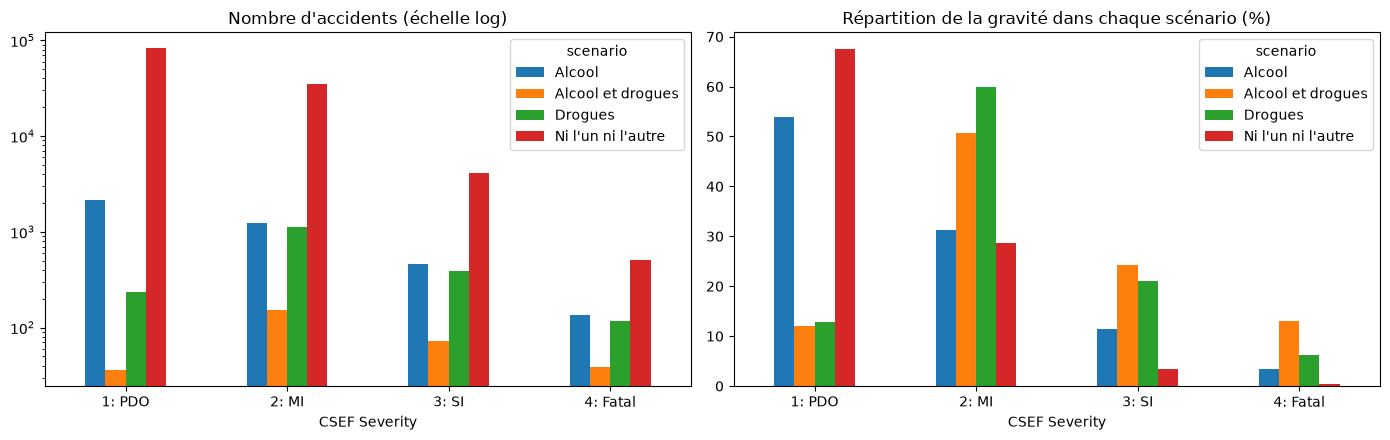

scenario,Alcool,Alcool et drogues,Drogues,Ni l'un ni l'autre
CSEF Severity,,,,
1: PDO,53.88,12.08,12.78,67.49
2: MI,31.24,50.67,59.82,28.74
3: SI,11.46,24.16,21.09,3.36
4: Fatal,3.42,13.09,6.31,0.42


In [15]:
# Seul le petit résultat agrégé (16 lignes) est ramené en pandas pour le graphique
pdf = severity_df.toPandas()
counts = pdf.pivot(index="CSEF Severity", columns="scenario", values="count")
percent = pdf.pivot(index="CSEF Severity", columns="scenario", values="percent")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
counts.plot(kind="bar", ax=axes[0], logy=True, title="Nombre d'accidents (échelle log)")
percent.plot(kind="bar", ax=axes[1], title="Répartition de la gravité dans chaque scénario (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
percent

**Lecture.** Sans alcool ni drogue, la grande majorité des accidents ne cause que des dégâts matériels (`1: PDO`).
Dès qu'alcool ou drogue sont détectés, la part des accidents graves (`3: SI`) et mortels (`4: Fatal`) augmente fortement,
et c'est le cumul alcool + drogues qui donne la plus forte proportion d'accidents mortels.
Attention : il s'agit d'une corrélation ; les conducteurs sont plus souvent testés après un accident grave, ce qui biaise vers le haut
la gravité observée chez les conducteurs positifs.

## 9. Mêmes requêtes avec RDD, DataFrame et Spark SQL

### Requête A – Date, heure, victimes, sexe, âge et type de permis des conducteurs pour le quartier ADELAIDE

In [16]:
def query_A_rdd():
    crash_kv = (crash_rdd.filter(lambda r: r[C["Suburb"]] == "ADELAIDE")
                .map(lambda r: (r[C["REPORT_ID"]], (f'{r[C["Year"]]}-{r[C["Month"]]}-{r[C["Day"]]}', r[C["Time"]], int(r[C["Total Cas"]])))))
    units_kv = units_rdd.map(lambda r: (r[U["REPORT_ID"]], (r[U["Sex"]], r[U["Age"]], r[U["Licence Type"]])))
    return crash_kv.join(units_kv).map(lambda kv: kv[1][0] + kv[1][1]).collect()

def query_A_df():
    return (crash_df.filter(col("Suburb") == "ADELAIDE").join(units_df, "REPORT_ID")
            .select(F.concat_ws("-", "Year", "Month", "Day").alias("Date"), "Time", "Total Cas", "Sex", "Age", "Licence Type")
            .collect())

units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")

def query_A_sql():
    return spark.sql("""
        SELECT concat_ws('-', Year, Month, Day) AS Date, Time, `Total Cas`, Sex, Age, `Licence Type`
        FROM crash_table c JOIN units_table u ON u.REPORT_ID = c.REPORT_ID
        WHERE c.Suburb = 'ADELAIDE'
    """).collect()

res_A = {"RDD": query_A_rdd(), "DataFrame": query_A_df(), "SQL": query_A_sql()}
print({k: len(v) for k, v in res_A.items()})
res_A["SQL"][:5]

{'RDD': 11965, 'DataFrame': 11965, 'SQL': 11965}


[Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='084', Licence Type='Full'),
 Row(Date='2012-January-Monday', Time='08:45 am', Total Cas=0, Sex='Male', Age='040', Licence Type='Full'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='047', Licence Type='Full'),
 Row(Date='2012-January-Friday', Time='05:45 pm', Total Cas=0, Sex='Male', Age='XXX', Licence Type=None),
 Row(Date='2012-January-Friday', Time='07:30 pm', Total Cas=1, Sex='Female', Age='018', Licence Type='Provisional 2')]

L'article filtre sur ADELAIDE **après** la jointure ; ici le filtre est appliqué avant (côté RDD à la main, côté DataFrame/SQL Catalyst le fait automatiquement : *predicate pushdown*), ce qui réduit le volume joint.

### Requête B – Total des victimes par quartier quand le conducteur n'a pas de permis

**Correction de l'article** : dans sa version « trois API », l'article garde au contraire les conducteurs *dont le permis est connu*
(et utilise `COUNT` au lieu de `SUM`), ce qui ne répond pas à la question. On reprend la définition de la §8.5 :
`Licence Type == 'Unlicenced'` et somme de `Total Cas`.

In [17]:
def query_B_rdd():
    unlicensed = (units_rdd.filter(lambda r: r[U["Licence Type"]] == "Unlicenced")
                  .map(lambda r: (r[U["REPORT_ID"]], 1)))
    crash_kv = crash_rdd.map(lambda r: (r[C["REPORT_ID"]], (r[C["Suburb"]], int(r[C["Total Cas"]]))))
    return dict(unlicensed.join(crash_kv)
                .map(lambda kv: kv[1][1])
                .reduceByKey(lambda a, b: a + b).collect())

def query_B_df():
    return {r["Suburb"]: r["Total casualty"] for r in unlicensed_df.collect()}

def query_B_sql():
    rows = spark.sql("""
        SELECT Suburb, SUM(`Total Cas`) AS total
        FROM crash_table c JOIN units_table u ON u.REPORT_ID = c.REPORT_ID
        WHERE `Licence Type` = 'Unlicenced'
        GROUP BY Suburb
    """).collect()
    return {r["Suburb"]: r["total"] for r in rows}

res_B = {"RDD": query_B_rdd(), "DataFrame": query_B_df(), "SQL": query_B_sql()}
print({k: len(v) for k, v in res_B.items()})
sorted(res_B["SQL"].items(), key=lambda x: -x[1])[:10]

{'RDD': 752, 'DataFrame': 752, 'SQL': 752}


[('ADELAIDE', 43),
 ('SALISBURY', 30),
 ('PROSPECT', 27),
 ('INGLE FARM', 22),
 ('SALISBURY EAST', 20),
 ('MORPHETT VALE', 20),
 ('MURRAY BRIDGE', 19),
 ('DRY CREEK', 19),
 ('NORTH ADELAIDE', 17),
 ('MAWSON LAKES', 17)]

## 10. Tests

On vérifie automatiquement que :
1. les comptes Spark sont identiques à une lecture indépendante avec le module `csv` de Python ;
2. RDD et DataFrame lisent le même nombre de lignes ;
3. le partitionnement SA / autres ne perd aucune ligne ;
4. le comptage de mots est cohérent avec le comptage des types ;
5. la somme des niveaux de gravité égale le nombre total d'accidents, et chaque scénario totalise 100 % ;
6. les trois API donnent **exactement** le même résultat pour les requêtes A et B ;
7. le calcul de victimes sans permis est confirmé en pandas.

In [18]:
import glob
from collections import Counter

def read_all(pattern):
    rows = []
    for f in sorted(glob.glob(pattern)):
        with open(f, newline="", encoding="utf-8", errors="replace") as fh:
            rows += list(csv.DictReader(fh))
    return rows

py_crash, py_units = read_all("crash_data/*.csv"), read_all("units_data/*.csv")

# 1 et 2
assert crash_rdd.count() == crash_df.count() == len(py_crash)
assert units_rdd.count() == units_df.count() == len(py_units)
# 3
assert sum(partition_sizes) == len(py_units)
assert partition_sizes[0] == sum(1 for r in py_units if r["Lic State"] == "SA")
# 4
type_counts = Counter(r["Crash Type"] for r in py_crash)
assert dict(words.collect())["rear"] == sum(n for t, n in type_counts.items() if "rear" in t.lower().split())
# 5
sev = {r["CSEF Severity"]: r["count"] for r in crash_df.groupBy("CSEF Severity").count().collect()}
assert sum(sev.values()) == len(py_crash)
for s, total in pdf.groupby("scenario")["percent"].sum().items():
    assert abs(total - 100) < 0.05, (s, total)
# 6
# spark.read.csv lit les champs vides comme null, alors que le RDD garde '' : on les rend comparables
norm = lambda rows: sorted(tuple("" if x is None else str(x) for x in r) for r in rows)
assert norm(res_A["RDD"]) == norm(res_A["DataFrame"]) == norm(res_A["SQL"])
assert res_B["RDD"] == res_B["DataFrame"] == res_B["SQL"]
# 7
pc = pd.DataFrame(py_crash)[["REPORT_ID", "Suburb", "Total Cas"]].astype({"Total Cas": int})
pu = pd.DataFrame(py_units)
expected = pc.merge(pu[pu["Licence Type"] == "Unlicenced"], on="REPORT_ID").groupby("Suburb")["Total Cas"].sum().to_dict()
assert res_B["SQL"] == expected

print("Tous les tests passent ✔")
print("Accidents :", len(py_crash), "| unités :", len(py_units), "| gravité :", sev)

Tous les tests passent ✔
Accidents : 127672 | unités : 272591 | gravité : {'4: Fatal': 722, '2: MI': 37300, '1: PDO': 84775, '3: SI': 4875}


## 11. Comparaison des performances

Chaque requête est exécutée 3 fois avec chaque API (DataFrames en cache ; les RDD relisent les CSV, voir §6.1) ; on garde le meilleur temps.
On ajoute pandas (un seul cœur, tout en mémoire) comme référence non distribuée.

In [19]:
def best_time(fn, n=3):
    best = float("inf")
    for _ in range(n):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best

def wordcount_rdd():
    return words_fn().collect()
words_fn = lambda: (crash_rdd.flatMap(lambda r: r[C["Crash Type"]].lower().split())
                    .map(lambda w: (w, 1)).reduceByKey(lambda a, b: a + b))
wordcount_df  = lambda: (crash_df.select(F.explode(F.split(F.lower(col("Crash Type")), " ")).alias("w"))
                         .groupBy("w").count().collect())
wordcount_sql = lambda: spark.sql("""SELECT w, COUNT(*) FROM
                         (SELECT explode(split(lower(`Crash Type`), ' ')) AS w FROM crash_table) GROUP BY w""").collect()
wordcount_pd  = lambda: pd.DataFrame(py_crash)["Crash Type"].str.lower().str.split().explode().value_counts()

pdA = lambda: pc[pc["Suburb"] == "ADELAIDE"].merge(pu, on="REPORT_ID")
pdB = lambda: pc.merge(pu[pu["Licence Type"] == "Unlicenced"], on="REPORT_ID").groupby("Suburb")["Total Cas"].sum()

timings = pd.DataFrame({
    "Comptage de mots (Crash Type)": [best_time(wordcount_rdd), best_time(wordcount_df), best_time(wordcount_sql), best_time(wordcount_pd)],
    "A – jointure ADELAIDE":         [best_time(query_A_rdd),   best_time(query_A_df),   best_time(query_A_sql),   best_time(pdA)],
    "B – sans permis par quartier":  [best_time(query_B_rdd),   best_time(query_B_df),   best_time(query_B_sql),   best_time(pdB)],
}, index=["RDD", "DataFrame", "Spark SQL", "pandas"]).round(3)
timings

,Comptage de mots (Crash Type),A – jointure ADELAIDE,B – sans permis par quartier
RDD,14.051,43.287,54.887
DataFrame,0.376,0.191,0.041
Spark SQL,0.400,0.207,1.096
pandas,0.831,0.063,0.084


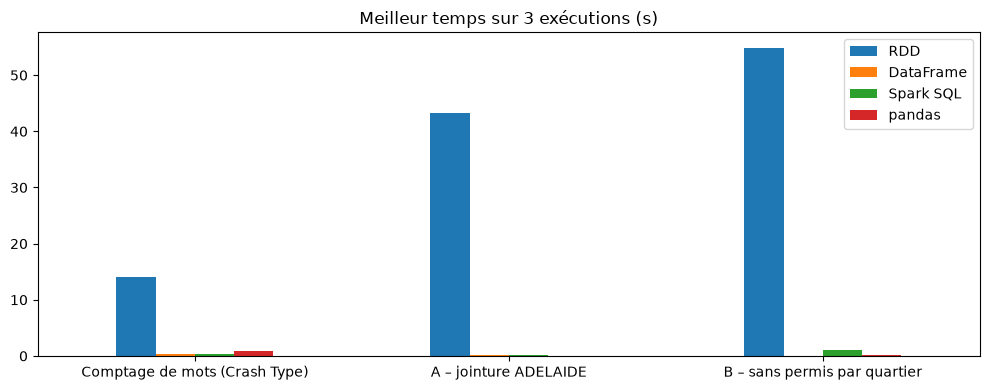

In [20]:
ax = timings.T.plot(kind="bar", figsize=(10, 4), title="Meilleur temps sur 3 exécutions (s)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

### 11.1 Analyse

Mesures obtenues sur la machine du TP (12 cœurs, Windows, `local[*]`) :

- **DataFrame et Spark SQL** sont dans le même ordre de grandeur (0,04 à 0,4 s) : ils passent par le même optimiseur Catalyst.
  L'écart sur la requête B (1,1 s en SQL contre 0,04 s en DataFrame) n'est pas structurel : à l'échelle de la seconde,
  le bruit (planification des tâches, ramasse-miettes JVM) pèse autant que le calcul lui-même.
- **RDD** est 30 à 1 000 fois plus lent : chaque ligne est sérialisée vers un processus Python, il n'y a ni optimiseur ni format colonne,
  la jointure RDD mélange (*shuffle*) les deux tables entières alors que le DataFrame diffuse la petite (*broadcast join*), et ici
  les RDD relisent les CSV à chaque requête (pas de cache possible sous Windows, §6.1). Sous Windows, le lancement des workers Python
  est en plus particulièrement coûteux.
- **pandas** est très compétitif : 127 672 accidents et 272 591 unités tiennent largement en mémoire et il n'y a aucun coût de
  planification. Il est même plus lent que Spark sur le comptage de mots (traitement de chaînes en Python pur, sur un seul cœur).
  L'intérêt de Spark apparaît quand les données ne tiennent plus en mémoire d'une machine ou avec un cluster —
  exactement la remarque de l'article sur `toPandas()`.

| Critère | RDD | DataFrame | Spark SQL |
|---|---|---|---|
| Niveau d'abstraction | bas (objets Python, indices de colonnes) | haut (colonnes nommées, schéma) | haut (SQL) |
| Optimisation automatique | aucune | Catalyst + Tungsten | Catalyst + Tungsten |
| Lisibilité des requêtes A/B | faible (indices, tuples imbriqués) | bonne | très bonne |
| Contrôle du partitionnement | total (`partitionBy`, fonction perso) | `repartition` par colonne | via DataFrame |
| Performance mesurée | la plus lente | rapide | rapide (= DataFrame) |

## 12. Conclusion

Nous avons reproduit l'étude de Rakesh Nain sur les 127 672 accidents de la route d'Australie-Méridionale (2012–2019) :

- **Résultats** : la partition « permis SA » domine logiquement ; l'âge moyen des conducteurs est le même pour les deux sexes ;
  les collisions par l'arrière sont les plus fréquentes mais les sorties de route et collisions frontales sont les plus meurtrières ;
  la part d'accidents graves et mortels est bien plus élevée lorsque l'alcool et/ou des drogues sont détectés, maximale quand les deux le sont.
- **Corrections apportées** : lecture CSV robuste (module `csv` au lieu de `split(',')`) ; requête « sans permis » de la partie
  trois API corrigée (l'article sélectionnait les conducteurs avec permis et comptait au lieu de sommer) ; UDF Python remplacées par
  des fonctions natives et une fenêtre ; `groupByKey`/`sortByKey().collect()` remplacés par `reduceByKey`/`takeOrdered`.
- **Tests** : les trois API donnent des résultats identiques entre elles et identiques à une implémentation Python/pandas indépendante.
- **Comparaison** : comme pour le comptage de mots du TP2, DataFrame et SQL sont équivalents et plus rapides que les RDD ;
  les RDD restent utiles pour un contrôle fin (partitionnement personnalisé). À cette échelle, pandas suffit ;
  Spark se justifie pour des volumes qui dépassent la mémoire d'une machine.

In [21]:
spark.stop()